<a href="https://colab.research.google.com/github/hussainmaroof98-oss/used_phone_prize_prediction/blob/main/used_phone_price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df=pd.read_csv("/content/drive/MyDrive/used_device_data.csv")
df.describe()

,screen_size,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
count,3454.000000,3275.000000,3452.000000,3450.000000,3450.000000,3448.000000,3447.000000,3454.000000,3454.000000,3454.000000,3454.000000
mean,13.713115,9.460208,6.554229,54.573099,4.036122,3133.402697,182.751871,2015.965258,674.869716,4.364712,5.233107
std,3.805280,4.815461,6.970372,84.972371,1.365105,1299.682844,88.413228,2.298455,248.580166,0.588914,0.683637
min,5.080000,0.080000,0.000000,0.010000,0.020000,500.000000,69.000000,2013.000000,91.000000,1.536867,2.901422
25%,12.700000,5.000000,2.000000,16.000000,4.000000,2100.000000,142.000000,2014.000000,533.500000,4.033931,4.790342
50%,12.830000,8.000000,5.000000,32.000000,4.000000,3000.000000,160.000000,2015.500000,690.500000,4.405133,5.245892
75%,15.340000,13.000000,8.000000,64.000000,4.000000,4000.000000,185.000000,2018.000000,868.750000,4.755700,5.673718
max,30.710000,48.000000,32.000000,1024.000000,12.000000,9720.000000,855.000000,2020.000000,1094.000000,6.619433,7.847841


Internal memory is the most skewed, but weight, cameras and battery lean the same way too. Trick to remember: if mean > median by a lot, there’s a long right tail.

In [3]:
df.info()

df.shape
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3454 entries, 0 to 3453
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   device_brand           3454 non-null   object 
 1   os                     3454 non-null   object 
 2   screen_size            3454 non-null   float64
 3   4g                     3454 non-null   object 
 4   5g                     3454 non-null   object 
 5   rear_camera_mp         3275 non-null   float64
 6   front_camera_mp        3452 non-null   float64
 7   internal_memory        3450 non-null   float64
 8   ram                    3450 non-null   float64
 9   battery                3448 non-null   float64
 10  weight                 3447 non-null   float64
 11  release_year           3454 non-null   int64  
 12  days_used              3454 non-null   int64  
 13  normalized_used_price  3454 non-null   float64
 14  normalized_new_price   3454 non-null   float64
dtypes: f

,0
device_brand,0
os,0
screen_size,0
4g,0
5g,0
rear_camera_mp,179
front_camera_mp,2
internal_memory,4
ram,4
battery,6


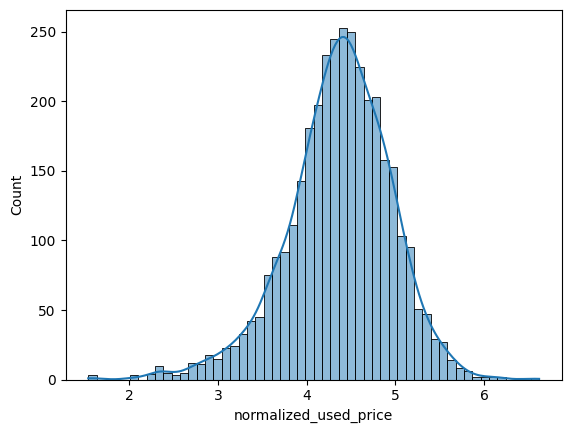

In [4]:

sns.histplot(df["normalized_used_price"], kde=True)
plt.show()

In [5]:

df["5g"].value_counts()

,count
5g,
no,3302
yes,152


In [6]:
df["device_brand"].value_counts()

,count
device_brand,
Others,502
Samsung,341
Huawei,251
LG,201
Lenovo,171
ZTE,140
Xiaomi,132
Oppo,129
Asus,122


there are 34 catogaries but we are one hot encoding cause we cant give the weightage to those companies on the basis of their popularity or we'll be supportin favroutism

In [7]:
df["os"].value_counts()


,count
os,
Android,3214
Others,137
Windows,67
iOS,36


In [8]:

df["4g"].value_counts()

,count
4g,
yes,2335
no,1119


In [9]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()
corr["normalized_used_price"].sort_values(ascending=False)

,normalized_used_price
normalized_used_price,1.000000
normalized_new_price,0.834496
screen_size,0.614785
battery,0.613619
front_camera_mp,0.608074
rear_camera_mp,0.587302
ram,0.520289
release_year,0.509790
weight,0.382354
internal_memory,0.190993


In [10]:
# 1. A number for skewness instead of eyeballing it
df.skew(numeric_only=True)

,0
screen_size,1.023932
rear_camera_mp,0.765506
front_camera_mp,1.801649
internal_memory,5.794750
ram,1.069178
battery,1.332270
weight,3.232498
release_year,0.322297
days_used,-0.343977
normalized_used_price,-0.532338


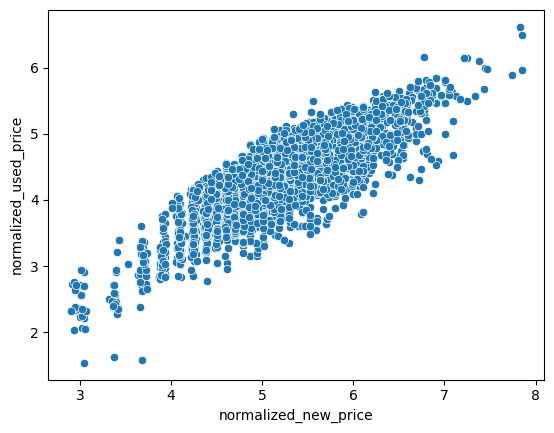

In [11]:
# 2. Does used price really follow new price?
sns.scatterplot(x="normalized_new_price", y="normalized_used_price", data=df)
plt.show()

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop("normalized_used_price", axis=1)   # features
y = df["normalized_used_price"]                # target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(X_train.shape, X_test.shape)

(2763, 14) (691, 14)


In [13]:
# 3. Who are the phones with missing rear camera?
df[df["rear_camera_mp"].isnull()].head(5)
#we can adjust the value inside the head so to view wider range of data

,device_brand,os,screen_size,4g,5g,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_used_price,normalized_new_price
59,Infinix,Android,17.32,yes,no,NaN,8.0,32.0,2.0,6000.0,209.0,2020,245,4.282068,4.597642
60,Infinix,Android,15.39,yes,no,NaN,8.0,64.0,4.0,5000.0,185.0,2020,173,4.363608,4.711780
61,Infinix,Android,15.39,yes,no,NaN,8.0,32.0,2.0,5000.0,185.0,2020,256,4.181439,4.505460
62,Infinix,Android,15.39,yes,no,NaN,16.0,32.0,3.0,4000.0,178.0,2019,316,4.555244,4.602166
63,Infinix,Android,15.29,yes,no,NaN,16.0,32.0,2.0,4000.0,165.0,2019,468,4.416670,4.871297


rear camera are missing from the phones from 2020-2019 mostly

In [14]:
# Which years have the missing rear cameras?
df[df["rear_camera_mp"].isnull()]["release_year"].value_counts()



,count
release_year,
2020,122
2019,45
2018,10
2017,2


In [15]:
# Does the typical rear camera change by year?
df.groupby("release_year")["rear_camera_mp"].median()

,rear_camera_mp
release_year,
2013,5.0
2014,8.0
2015,8.0
2016,13.0
2017,13.0
2018,13.0
2019,12.2
2020,8.0


In [16]:
#old phones have lower pixels and newer phones have higher pixels so we cant fill it with midean of all the years of data

most of the nan are from 2019 and 2020 and mean ofc differs from years cause as years passes by everythinng improves so we have to fill everything acc to that year right? but ig we have to fill only this column like that cause we can either drop or fill other columns simply without taking mean of each years they belongs to

In [17]:
df["release_year"].value_counts().sort_index()

,count
release_year,
2013,570
2014,642
2015,515
2016,383
2017,299
2018,322
2019,446
2020,277


Fill with the median of that phone’s release year, and if that year has no median (can’t happen here, but it’s a safety net), fall back to the overall median

In [18]:
cols_to_fill = ["rear_camera_mp", "front_camera_mp", "internal_memory",
                "ram", "battery", "weight"]

# 1. Learn the fill values from TRAIN only
year_medians = X_train.groupby("release_year")[cols_to_fill].median()
overall_medians = X_train[cols_to_fill].median()

# 2. A reusable function that applies them
def fill_missing(data):
    data = data.copy()
    for col in cols_to_fill:
        per_year = data["release_year"].map(year_medians[col])
        data[col] = data[col].fillna(per_year)
        data[col] = data[col].fillna(overall_medians[col])
    return data

# 3. Apply the SAME fill values to both sets
X_train = fill_missing(X_train)
X_test = fill_missing(X_test)

print(X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

0 0


In [19]:
#one hot encoding for catogorical columns

In [20]:
cat_cols = ["device_brand", "os", "4g", "5g"]

X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)

# make the test columns match the train columns exactly
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print(X_train.shape, X_test.shape)
X_train.head()

(2763, 48) (691, 48)


,screen_size,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_new_price,...,device_brand_Spice,device_brand_Vivo,device_brand_XOLO,device_brand_Xiaomi,device_brand_ZTE,os_Others,os_Windows,os_iOS,4g_yes,5g_yes
1295,25.60,13.0,8.0,64.0,4.0,7500.0,498.0,2018,537,5.968119,...,0,0,0,0,0,0,0,0,1,0
2319,10.34,8.0,2.0,32.0,4.0,2100.0,150.0,2014,1026,4.620847,...,0,0,0,0,0,0,0,0,0,0
1650,12.83,13.0,5.0,64.0,4.0,3000.0,149.0,2017,746,5.021641,...,0,0,0,0,0,0,0,0,1,0
581,12.70,13.0,5.0,16.0,4.0,2350.0,128.0,2015,725,5.297967,...,0,0,0,0,0,0,0,0,1,0
3285,16.36,8.0,16.0,128.0,6.0,4400.0,214.5,2020,154,6.191667,...,0,1,0,0,0,0,0,0,1,1


In [ ]:
#scaling for numerical columns because values of each column differ widely


In [21]:
from sklearn.preprocessing import StandardScaler

num_cols = ["screen_size", "rear_camera_mp", "front_camera_mp",
            "internal_memory", "ram", "battery", "weight",
            "release_year", "days_used", "normalized_new_price"]

# keep unscaled copies, useful later for tree models
X_train_raw = X_train.copy()
X_test_raw = X_test.copy()

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train[num_cols].describe().round(2)

,screen_size,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_new_price
count,2763.00,2763.00,2763.00,2763.00,2763.00,2763.00,2763.00,2763.00,2763.00,2763.00
mean,0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.24,-1.98,-0.95,-0.64,-2.99,-2.03,-1.27,-1.30,-2.37,-3.38
25%,-0.26,-0.94,-0.66,-0.45,-0.03,-0.79,-0.46,-0.86,-0.56,-0.64
50%,-0.23,-0.31,-0.22,-0.26,-0.03,-0.10,-0.26,0.01,0.05,0.02
75%,0.42,0.75,0.21,0.11,-0.03,0.67,0.02,0.89,0.77,0.65
max,4.42,8.14,3.70,11.28,5.93,5.09,7.50,1.76,1.69,3.80


In [25]:
X_train.describe()

,screen_size,rear_camera_mp,front_camera_mp,internal_memory,ram,battery,weight,release_year,days_used,normalized_new_price,...,device_brand_Spice,device_brand_Vivo,device_brand_XOLO,device_brand_Xiaomi,device_brand_ZTE,os_Others,os_Windows,os_iOS,4g_yes,5g_yes
count,2.763000e+03,2.763000e+03,2.763000e+03,2.763000e+03,2.763000e+03,2.763000e+03,2.763000e+03,2.763000e+03,2.763000e+03,2.763000e+03,...,2763.000000,2763.000000,2763.000000,2763.000000,2763.000000,2763.000000,2763.000000,2763.000000,2763.000000,2763.000000
mean,2.725933e-16,2.340188e-16,4.628943e-17,-5.143270e-18,4.526078e-16,-1.504406e-16,2.957380e-17,-2.481628e-15,-1.208668e-16,-4.963255e-16,...,0.007962,0.033297,0.015201,0.036916,0.041621,0.040536,0.020630,0.010496,0.678248,0.041983
std,1.000181e+00,1.000181e+00,1.000181e+00,1.000181e+00,1.000181e+00,1.000181e+00,1.000181e+00,1.000181e+00,1.000181e+00,1.000181e+00,...,0.088892,0.179444,0.122373,0.188591,0.199759,0.197248,0.142167,0.101929,0.467233,0.200587
min,-2.243741e+00,-1.981771e+00,-9.465414e-01,-6.350190e-01,-2.992314e+00,-2.028885e+00,-1.272539e+00,-1.300285e+00,-2.367558e+00,-3.382618e+00,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-2.624544e-01,-9.424045e-01,-6.563885e-01,-4.496092e-01,-2.823716e-02,-7.936150e-01,-4.574966e-01,-8.626859e-01,-5.613737e-01,-6.385161e-01,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,-2.286529e-01,-3.086441e-01,-2.211590e-01,-2.635015e-01,-2.823716e-02,-9.877539e-02,-2.565272e-01,1.251188e-02,5.280962e-02,2.357324e-02,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,4.239757e-01,7.476231e-01,2.140705e-01,1.087139e-01,-2.823716e-02,6.732686e-01,2.259704e-02,8.877097e-01,7.720506e-01,6.469934e-01,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,4.420351e+00,8.141494e+00,3.695906e+00,1.127518e+01,5.929706e+00,5.089360e+00,7.503126e+00,1.762907e+00,1.685244e+00,3.804249e+00,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

lr = LinearRegression()
lr.fit(X_train, y_train)          # learn the weights from TRAIN only

train_pred = lr.predict(X_train)
test_pred = lr.predict(X_test)

In [27]:
print("Train R2:", round(r2_score(y_train, train_pred), 4))
print("Test  R2:", round(r2_score(y_test, test_pred), 4))
print("Test RMSE:", round(np.sqrt(mean_squared_error(y_test, test_pred)), 4))

coef = pd.Series(lr.coef_, index=X_train.columns).sort_values()
print(coef.head(5))   # most negative effects
print(coef.tail(5))   # most positive effects

Train R2: 0.8464
Test  R2: 0.8358
Test RMSE: 0.2309
device_brand_Celkon   -0.187452
device_brand_Google   -0.093561
os_Others             -0.088018
os_iOS                -0.086142
device_brand_Sony     -0.076437
dtype: float64
weight                  0.074410
front_camera_mp         0.086781
rear_camera_mp          0.100005
screen_size             0.108604
normalized_new_price    0.292146
dtype: float64


In [28]:
from sklearn.linear_model import RidgeCV, LassoCV

ridge = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5)
ridge.fit(X_train, y_train)

lasso = LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1], cv=5, max_iter=10000)
lasso.fit(X_train, y_train)

for name, m in [("Ridge", ridge), ("Lasso", lasso)]:
    tr = m.predict(X_train)
    te = m.predict(X_test)
    print(name, "| best alpha:", m.alpha_)
    print("  Train R2:", round(r2_score(y_train, tr), 4))
    print("  Test  R2:", round(r2_score(y_test, te), 4))
    print("  Test RMSE:", round(np.sqrt(mean_squared_error(y_test, te)), 4))

# Lasso: which features did it throw away?
lasso_coef = pd.Series(lasso.coef_, index=X_train.columns)
print("Features Lasso zeroed out:", (lasso_coef == 0).sum(), "of", len(lasso_coef))
print(lasso_coef[lasso_coef == 0].index.tolist())

Ridge | best alpha: 100.0
  Train R2: 0.8443
  Test  R2: 0.8378
  Test RMSE: 0.2294
Lasso | best alpha: 0.001
  Train R2: 0.8444
  Test  R2: 0.8377
  Test RMSE: 0.2295
Features Lasso zeroed out: 27 of 48
['device_brand_Apple', 'device_brand_BlackBerry', 'device_brand_Coolpad', 'device_brand_Gionee', 'device_brand_Google', 'device_brand_HTC', 'device_brand_Honor', 'device_brand_Huawei', 'device_brand_Infinix', 'device_brand_Karbonn', 'device_brand_Lava', 'device_brand_Meizu', 'device_brand_Micromax', 'device_brand_Microsoft', 'device_brand_Motorola', 'device_brand_OnePlus', 'device_brand_Oppo', 'device_brand_Panasonic', 'device_brand_Realme', 'device_brand_Sony', 'device_brand_Spice', 'device_brand_Vivo', 'device_brand_XOLO', 'device_brand_ZTE', 'os_Windows', 'os_iOS', '5g_yes']
